###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_letters_A_J" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 10

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim)
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 110
[10 11 12 13 14 15 16 17 18 19]


### Parameters

In [5]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [6]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [7]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 62.229770
Epoch: 1, Loss: 38.361054
Epoch: 2, Loss: 26.819958
Epoch: 3, Loss: 18.645822
Epoch: 4, Loss: 12.864467
Epoch: 5, Loss: 8.846574
Epoch: 6, Loss: 6.152767
Epoch: 7, Loss: 4.431398
Epoch: 8, Loss: 3.393500
Epoch: 9, Loss: 2.743665
Epoch: 10, Loss: 2.416266
Epoch: 11, Loss: 2.223688
Epoch: 12, Loss: 2.133084
Epoch: 13, Loss: 2.081664
Epoch: 14, Loss: 2.046106
Epoch: 15, Loss: 2.027224
Epoch: 16, Loss: 2.002013
Epoch: 17, Loss: 2.000490
Epoch: 18, Loss: 1.989198
Epoch: 19, Loss: 1.974004
Epoch: 20, Loss: 1.950605
Epoch: 21, Loss: 1.948910
Epoch: 22, Loss: 1.946131
Epoch: 23, Loss: 1.919362
Epoch: 24, Loss: 1.929635
Epoch: 25, Loss: 1.902311
Epoch: 26, Loss: 1.903541
Epoch: 27, Loss: 1.887220
Epoch: 28, Loss: 1.859791
Epoch: 29, Loss: 1.854102
Epoch: 30, Loss: 1.837118
Epoch: 31, Loss: 1.820915
Epoch: 32, Loss: 1.830544
Epoch: 33, Loss: 1.818338
Epoch: 34, Loss: 1.811145
Epoch: 35, Loss: 1.831223
Epoch: 36, Loss: 1.783752
Epoch: 37, Loss: 1.801086
Epoch: 38, Loss: 

### Initialize the clustering layer using k-means

In [8]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.75 PUR: 0.75 NMI: 0.66 ARI: 0.57


### Train Autoencoder

In [9]:
latent_data, labels, clustering = autoencoder.train_autoencoder()

Ep: 0 Rec L: 1.5047 Cl L: 1.1384 Entropy: 3.5722 SSil: -0.0384 ACC: 0.75 PUR: 0.75 NMI: 0.66 ARI: 0.57
Ep: 1 Rec L: 1.5098 Cl L: 1.1506 Entropy: 3.5190 SSil: -0.0506 ACC: 0.75 PUR: 0.75 NMI: 0.66 ARI: 0.57
Ep: 2 Rec L: 1.4913 Cl L: 1.1579 Entropy: 3.4910 SSil: -0.0579 ACC: 0.74 PUR: 0.74 NMI: 0.66 ARI: 0.56
Ep: 3 Rec L: 1.4899 Cl L: 1.1642 Entropy: 3.4678 SSil: -0.0642 ACC: 0.74 PUR: 0.74 NMI: 0.65 ARI: 0.55
Ep: 4 Rec L: 1.4863 Cl L: 1.1713 Entropy: 3.4416 SSil: -0.0713 ACC: 0.74 PUR: 0.74 NMI: 0.65 ARI: 0.55
Ep: 5 Rec L: 1.4933 Cl L: 1.1795 Entropy: 3.4084 SSil: -0.0795 ACC: 0.74 PUR: 0.74 NMI: 0.65 ARI: 0.55
Ep: 6 Rec L: 1.4858 Cl L: 1.1877 Entropy: 3.3602 SSil: -0.0877 ACC: 0.75 PUR: 0.75 NMI: 0.66 ARI: 0.56
Ep: 7 Rec L: 1.5103 Cl L: 1.1951 Entropy: 3.2864 SSil: -0.0951 ACC: 0.77 PUR: 0.77 NMI: 0.68 ARI: 0.58
Ep: 8 Rec L: 1.5341 Cl L: 1.1990 Entropy: 3.1562 SSil: -0.0990 ACC: 0.78 PUR: 0.78 NMI: 0.69 ARI: 0.61
Ep: 9 Rec L: 1.5784 Cl L: 1.1898 Entropy: 2.9387 SSil: -0.0898 ACC: 0.80 

### Save Clustering Results

In [10]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_letters_A_J/SSAE/100_Eps_ld_10_out_10_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 28010 samples in 0.014s...
[t-SNE] Computed neighbors for 28010 samples in 0.934s...
[t-SNE] Computed conditional probabilities for sample 1000 / 28010
[t-SNE] Computed conditional probabilities for sample 2000 / 28010
[t-SNE] Computed conditional probabilities for sample 3000 / 28010
[t-SNE] Computed conditional probabilities for sample 4000 / 28010
[t-SNE] Computed conditional probabilities for sample 5000 / 28010
[t-SNE] Computed conditional probabilities for sample 6000 / 28010
[t-SNE] Computed conditional probabilities for sample 7000 / 28010
[t-SNE] Computed conditional probabilities for sample 8000 / 28010
[t-SNE] Computed conditional probabilities for sample 9000 / 28010
[t-SNE] Computed conditional probabilities for sample 10000 / 28010
[t-SNE] Computed conditional probabilities for sample 11000 / 28010
[t-SNE] Computed conditional probabilities for sample 12000 / 28010
[t-SNE] Computed conditional probabilities for sam

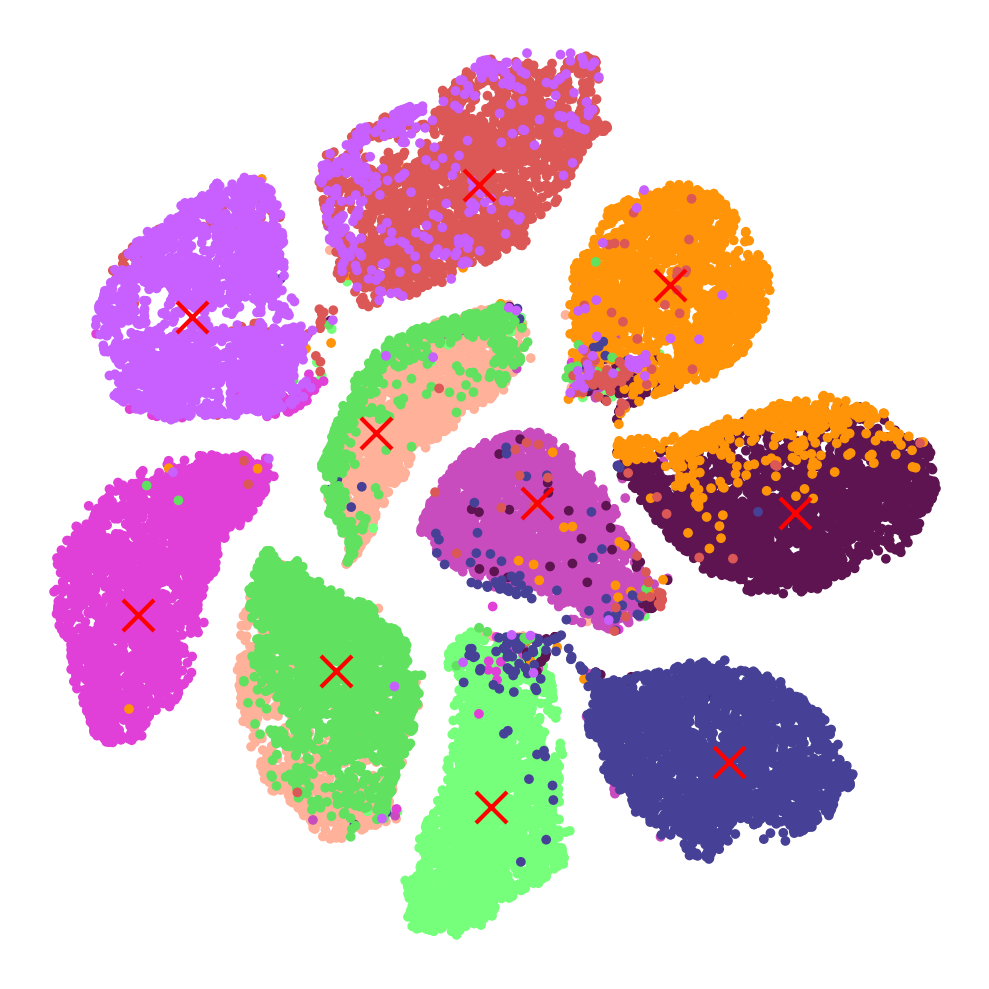

In [11]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)